# ACME Talent Insights (Gold layer)

Answers business questions Q1–Q7 from the **Gold** datasets only (definitions: [DESIGN.md](../docs/DESIGN.md)).

**Language rules:** *recorded* = value from the source system; `derived_` = calculated by the pipeline. Q5/Q6 show **association, not causation**; nothing here is a prediction. Q3 is an **analytic shortlist, not an HR decision**.

In [1]:
import json
import os
from decimal import Decimal

import matplotlib.pyplot as plt
import pandas as pd
from pyarrow import fs

%matplotlib inline
pd.set_option("display.width", 140)

# LAKE_ROOT: a local folder (default ../lake) or s3://bucket/prefix (s3a:// also accepted).
# S3 credentials come only from the standard AWS environment/profile chain, never from this notebook.
LAKE_ROOT = os.environ.get("LAKE_ROOT", "../lake")
if LAKE_ROOT.startswith(("s3://", "s3a://")):
    FS = fs.S3FileSystem(region=os.environ.get("AWS_REGION", "ap-south-1"))
    ROOT = LAKE_ROOT.split("://", 1)[1].rstrip("/")
else:
    FS = fs.LocalFileSystem()
    ROOT = os.path.abspath(LAKE_ROOT)
print(f"Reading the lake from {LAKE_ROOT}")


def gold(name: str) -> pd.DataFrame:
    """Read one Gold dataset; Spark decimals arrive as Python Decimal -> cast to float."""
    df = pd.read_parquet(f"{ROOT}/gold/{name}", filesystem=FS)
    for col in df.columns:
        if df[col].dtype == object and df[col].dropna().map(lambda v: isinstance(v, Decimal)).any():
            df[col] = df[col].astype(float)
    return df


def latest_manifest() -> dict:
    """Manifest of the newest run (highest run_id= folder under _runs/), written by Spark as JSON text."""
    runs = [i.path for i in FS.get_file_info(fs.FileSelector(f"{ROOT}/_runs"))
            if i.type == fs.FileType.Directory and i.base_name.startswith("run_id=")]
    newest = max(runs)
    part = next(i.path for i in FS.get_file_info(fs.FileSelector(newest))
                if i.base_name.startswith("part-") and i.base_name.endswith(".txt"))
    with FS.open_input_stream(part) as f:
        return json.loads(f.read().decode("utf-8"))

Reading the lake from ../lake


## Data quality: what the latest run read, kept, quarantined and deduplicated

In [2]:
manifest = latest_manifest()
steps = pd.DataFrame(manifest["steps"]).set_index("step")
cols = ["rows_read", "rows_written", "rows_quarantined", "rows_deduped", "rows_warned"]
print(f"run_id={manifest['run_id']}  status={manifest['status']}  duration_s={manifest['duration_s']}")
display(steps[cols])

le = manifest["steps"][[s["step"] for s in manifest["steps"]].index("silver.learning_events")]
q = json.loads(le["note"])["quarantine_by_rule"]
malformed = q["learning_events.raw.malformed_json"]
null_emp = q["learning_events.employee_id.not_null"]
bad_date = q["learning_events.event_ts.invalid"]
print(f"Learning reconciliation: {le['rows_read']:,} lines = {malformed} malformed + "
      f"{le['rows_deduped']} duplicates + {null_emp} null employee + {bad_date} invalid date + "
      f"{le['rows_written']:,} valid")
assert le["rows_read"] == malformed + le["rows_deduped"] + null_emp + bad_date + le["rows_written"]

run_id=20261015T200647Z-1be11b  status=SUCCESS  duration_s=70.025


,rows_read,rows_written,rows_quarantined,rows_deduped,rows_warned
step,,,,,
bronze.hr.employees,2000,2000,0,0,0
bronze.hr.teams,100,100,0,0,0
bronze.hr.competencies,40,40,0,0,0
bronze.hr.projects,33,33,0,0,0
bronze.hr.performance_reviews,4000,4000,0,0,0
bronze.hr.competency_assessments,4000,4000,0,0,0
bronze.hr.talent_review,2000,2000,0,0,0
bronze.learning_activity,29868,29868,0,0,0
silver.hr.teams,100,100,0,0,0


Learning reconciliation: 29,868 lines = 13 malformed + 152 duplicates + 76 null employee + 53 invalid date + 29,574 valid


## Q1: How are employee ratings moving between review periods?

derived_rating_trend
improving    898
stable       872
declining    230
rating           1    2    3    4    5
review_period                         
2024-H2          0  650  663  687    0
2025-H1        112  354  530  605  399


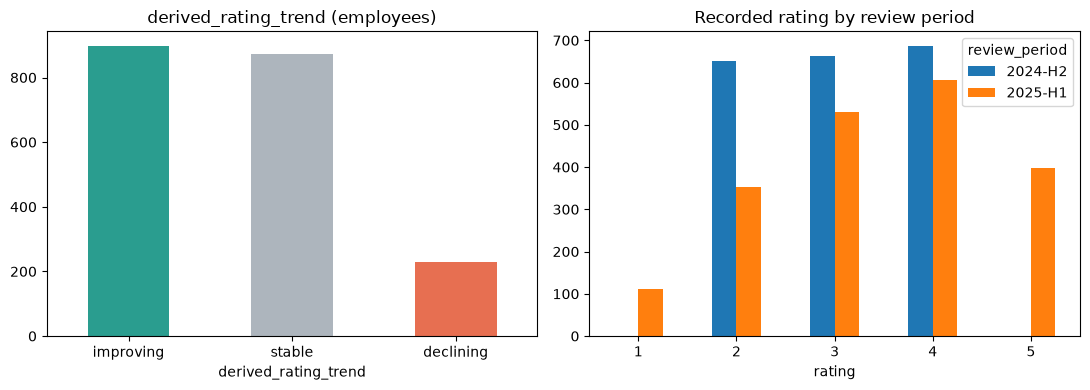

In [3]:
g1b = gold("employee_performance_summary")
g1 = gold("employee_performance_history")
trend = g1b["derived_rating_trend"].value_counts().reindex(["improving", "stable", "declining"])
by_period = g1.groupby(["review_period", "rating"]).size().unstack(fill_value=0)
print(trend.to_string()); print(by_period)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
trend.plot.bar(ax=a, color=["#2a9d8f", "#adb5bd", "#e76f51"], rot=0, title="derived_rating_trend (employees)")
by_period.T.plot.bar(ax=b, rot=0, title="Recorded rating by review period")
b.set_xlabel("rating"); plt.tight_layout(); plt.show()

In [4]:
n = int(trend.sum()); periods = list(by_period.index)
avg = g1.groupby("review_period")["rating"].mean()
direction = "rose" if avg.iloc[-1] > avg.iloc[0] else "fell" if avg.iloc[-1] < avg.iloc[0] else "held"
print(f"Of {n:,} employees, {trend['improving']:,} improved, {trend['stable']:,} were stable and "
      f"{trend['declining']:,} declined between {periods[0]} and {periods[-1]}. "
      f"The average recorded rating {direction} from {avg.iloc[0]:.2f} to {avg.iloc[-1]:.2f}.")

Of 2,000 employees, 898 improved, 872 were stable and 230 declined between 2024-H2 and 2025-H1. The average recorded rating rose from 3.02 to 3.41.


*Caveat:* only two review periods exist, so a trend is a single change, not a long-run pattern.

## Q2: Where are the biggest competency gaps?

critical gaps (gap >= 2): 325 of 4,000 assessments
competency_name         competency_category
Strategic Thinking      Leadership             15
Stakeholder Management  Domain                 14
Incident Response       Technical              12
Negotiation             Domain                 12
Presentation Skills     Domain                 12
Risk Management         Domain                 12
Agile Practices         Domain                 11
Communication           Domain                 10
Machine Learning        Technical              10
People Leadership       Leadership             10
Performance Tuning      Technical              10
Project Management      Domain                 10
Technical Writing       Domain                 10


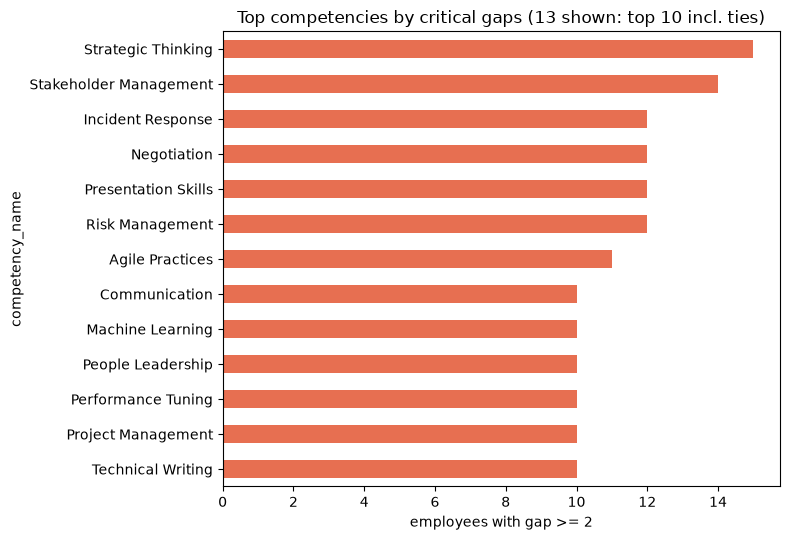

In [5]:
g2 = gold("employee_competency_gaps")
crit = g2[g2["derived_gap_severity"] == "critical"]
top10 = crit.groupby(["competency_name", "competency_category"]).size().nlargest(10, keep="all")  # ties kept
print(f"critical gaps (gap >= 2): {len(crit):,} of {len(g2):,} assessments")
print(top10.to_string())

ax = top10.droplevel(1).iloc[::-1].plot.barh(figsize=(8, 5.5), color="#e76f51",
                                              title=f"Top competencies by critical gaps ({len(top10)} shown: top 10 incl. ties)")
ax.set_xlabel("employees with gap >= 2"); plt.tight_layout(); plt.show()

In [6]:
first, first_n = top10.index[0][0], int(top10.iloc[0])
cats = top10.reset_index()["competency_category"].value_counts()
print(f"{len(crit):,} of {len(g2):,} assessments ({len(crit)/len(g2):.1%}) show a critical gap (required − proficiency ≥ 2). "
      f"'{first}' has the most critical gaps ({first_n}); {cats.idxmax()} competencies make up "
      f"{cats.max()} of the {len(top10)} competencies in the top 10 (ties included).")

325 of 4,000 assessments (8.1%) show a critical gap (required − proficiency ≥ 2). 'Strategic Thinking' has the most critical gaps (15); Domain competencies make up 8 of the 13 competencies in the top 10 (ties included).


*Caveat:* the critical threshold (2) is a pipeline parameter; the source has no 'key competency' flag, so importance is not weighted.

## Q3: Who is ready for promotion (analytic shortlist)?

promotion_readiness  Ready Now  1-2 Years  Not Ready
potential_rating                                    
High                       357        137        152
Medium                     198        334        306
Low                         96        217        203
shortlist (High + Ready Now): 357
      latest_rating  critical_gap_count  courses_completed
mean       3.333333             0.19888           1.745098
50%        3.000000             0.00000           2.000000


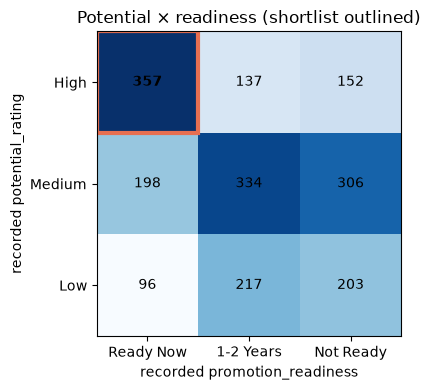

In [7]:
g3 = gold("promotion_readiness")
grid = pd.crosstab(g3["potential_rating"], g3["promotion_readiness"]).reindex(
    index=["High", "Medium", "Low"], columns=["Ready Now", "1-2 Years", "Not Ready"])
shortlist = g3[g3["derived_high_potential_ready_now"]]
print(grid); print(f"shortlist (High + Ready Now): {len(shortlist)}")
print(shortlist[["latest_rating", "critical_gap_count", "courses_completed"]].describe().loc[["mean", "50%"]])

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(grid.values, cmap="Blues")
ax.set_xticks(range(3), grid.columns); ax.set_yticks(range(3), grid.index)
for i in range(3):
    for j in range(3):
        ax.text(j, i, grid.values[i, j], ha="center", va="center",
                fontweight="bold" if (i, j) == (0, 0) else "normal")
ax.add_patch(plt.Rectangle((-0.5, -0.5), 1, 1, fill=False, edgecolor="#e76f51", lw=3))
ax.set_xlabel("recorded promotion_readiness"); ax.set_ylabel("recorded potential_rating")
ax.set_title("Potential × readiness (shortlist outlined)"); plt.tight_layout(); plt.show()

In [8]:
sl = shortlist
print(f"{len(sl)} of {len(g3):,} employees ({len(sl)/len(g3):.1%}) are recorded as High potential and Ready Now. "
      f"Their mean latest rating is {sl['latest_rating'].mean():.2f} (all employees: {g3['latest_rating'].mean():.2f}), "
      f"and {(sl['critical_gap_count'] > 0).mean():.0%} of them still have at least one critical competency gap.")

357 of 2,000 employees (17.8%) are recorded as High potential and Ready Now. Their mean latest rating is 3.33 (all employees: 3.41), and 19% of them still have at least one critical competency gap.


*Caveat:* an analytic shortlist from recorded talent-review values (one review cycle), not an HR decision.

## Q4: How much learning is completed, and which courses?

courses_completed
0    339
1    642
2    525
3    315
4    125
5     43
6      8
7      3
course_name
Agile Practices Certification        105
Cloud Architecture Fundamentals      103
Customer Empathy Workshop             95
Data Privacy Fundamentals             94
Time Management for Professionals     90
completion without enrollment: 3,255 employee×course pairs


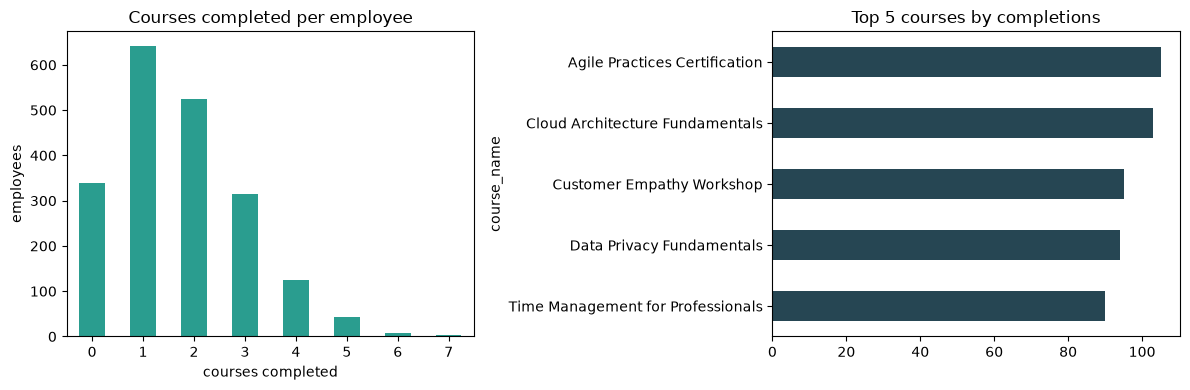

In [9]:
g4b = gold("learning_summary")
g4 = gold("learning_progress")
dist = g4b["courses_completed"].value_counts().sort_index()
top5 = g4[g4["is_course_completed"]].groupby("course_name").size().sort_values(ascending=False).head(5)
print(dist.to_string()); print(top5.to_string())
print(f"completion without enrollment: {int(g4['dq_completion_without_enrollment'].sum()):,} employee×course pairs")

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
dist.plot.bar(ax=a, rot=0, color="#2a9d8f", title="Courses completed per employee")
a.set_xlabel("courses completed"); a.set_ylabel("employees")
top5.iloc[::-1].plot.barh(ax=b, color="#264653", title="Top 5 courses by completions")
plt.tight_layout(); plt.show()

In [10]:
zero = int((g4b["courses_completed"] == 0).sum())
print(f"Employees completed {int(g4b['courses_completed'].sum()):,} courses in total (median {g4b['courses_completed'].median():.0f} per employee); "
      f"{zero:,} of {len(g4b):,} employees ({zero/len(g4b):.1%}) completed none. "
      f"'{top5.index[0]}' has the most completions ({int(top5.iloc[0])}).")

Employees completed 3,421 courses in total (median 2 per employee); 339 of 2,000 employees (17.0%) completed none. 'Agile Practices Certification' has the most completions (105).


*Caveat:* completion counts only `course_completed` events (modules/quizzes never imply completion); 3,255 pairs show a completion without an enrollment event; there is no course-to-competency mapping.

## Q5: How does the rating trend mix differ across recorded attrition-risk bands?

attrition_risk
Low       1077
Medium     612
High       311
derived_rating_trend  improving  stable  declining
attrition_risk                                    
Low                        49.6    48.8        1.7
Medium                     45.8    42.8       11.4
High                       27.0    27.3       45.7


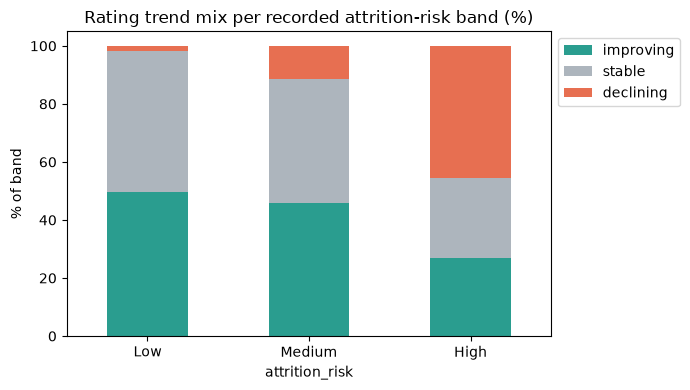

In [11]:
g5b = gold("attrition_by_trend")
mix = g5b.pivot(index="attrition_risk", columns="derived_rating_trend", values="pct_of_risk_band") \
         .reindex(index=["Low", "Medium", "High"], columns=["improving", "stable", "declining"]) * 100
bands = g5b.groupby("attrition_risk")["headcount"].sum().reindex(["Low", "Medium", "High"])
print(bands.to_string()); print(mix.round(1))

ax = mix.plot.bar(stacked=True, rot=0, figsize=(7, 4), color=["#2a9d8f", "#adb5bd", "#e76f51"],
                  title="Rating trend mix per recorded attrition-risk band (%)")
ax.set_ylabel("% of band"); ax.legend(loc="upper left", bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

In [12]:
hi, lo = mix.loc["High", "declining"], mix.loc["Low", "declining"]
print(f"Risk bands hold {bands['Low']:,} Low, {bands['Medium']:,} Medium and {bands['High']:,} High-risk employees. "
      f"{hi:.1f}% of the High band had a declining rating versus {lo:.1f}% of the Low band, "
      f"so declining ratings are {'more' if hi > lo else 'less'} common where recorded risk is higher.")

Risk bands hold 1,077 Low, 612 Medium and 311 High-risk employees. 45.7% of the High band had a declining rating versus 1.7% of the Low band, so declining ratings are more common where recorded risk is higher.


*Caveat:* association, not causation; attrition_risk is a recorded label, and this is not a prediction of who will leave.

## Q6: Do teams with higher ratings have better project outcomes?

teams with projects n=27 of 100; projects=33; Pearson r=0.240


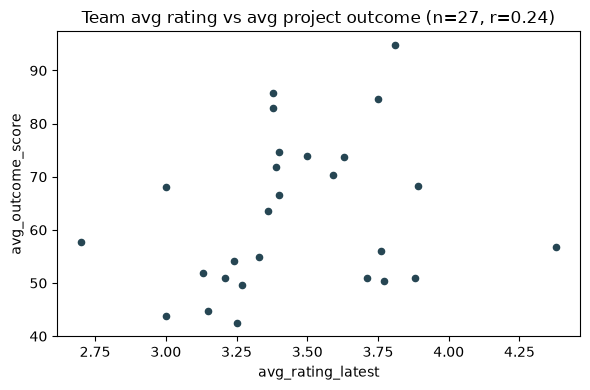

In [13]:
g6 = gold("team_performance_outcomes")
with_proj = g6[g6["has_projects"]]
r = with_proj["avg_rating_latest"].corr(with_proj["avg_outcome_score"])
print(f"teams with projects n={len(with_proj)} of {len(g6)}; projects={int(g6['project_count'].sum())}; Pearson r={r:.3f}")

ax = with_proj.plot.scatter(x="avg_rating_latest", y="avg_outcome_score", figsize=(6, 4), color="#264653",
                            title=f"Team avg rating vs avg project outcome (n={len(with_proj)}, r={r:.2f})")
plt.tight_layout(); plt.show()

In [14]:
strength = "weak" if abs(r) < 0.3 else "moderate" if abs(r) < 0.6 else "strong"
sign = "positive" if r > 0 else "negative"
print(f"Across the {len(with_proj)} teams that have projects, the correlation between average latest rating and "
      f"average project outcome score is r = {r:.2f}, a {strength} {sign} association. "
      f"{len(g6) - len(with_proj)} of {len(g6)} teams have no linked project, so they are excluded.")

Across the 27 teams that have projects, the correlation between average latest rating and average project outcome score is r = 0.24, a weak positive association. 73 of 100 teams have no linked project, so they are excluded.


*Caveat:* n=27 teams; projects link only to teams and have no dates; correlation is association, not causation.

## Q7: How well do assessed proficiencies meet requirements, by competency category?

assessed_count total = 4,000
                     meeting  assessed_count  pct_meeting
competency_category                                      
Domain                1542.0            2069         74.5
Technical              972.0            1293         75.2
Leadership             493.0             638         77.3


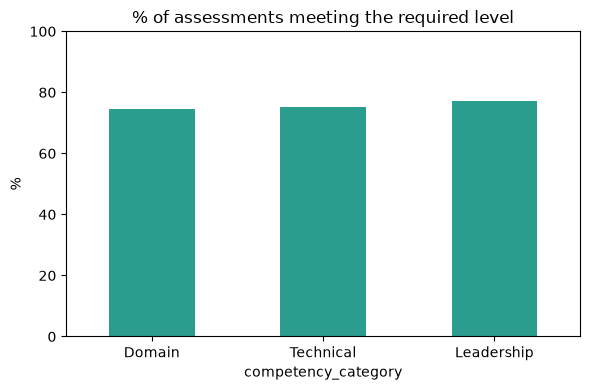

In [15]:
g7 = gold("competency_distribution")
g7["meeting"] = (g7["pct_meeting_requirement"] * g7["assessed_count"]).round()
cat = g7.groupby("competency_category")[["meeting", "assessed_count"]].sum()
cat["pct_meeting"] = cat["meeting"] / cat["assessed_count"] * 100
cat = cat.sort_values("pct_meeting")
print(f"assessed_count total = {int(g7['assessed_count'].sum()):,}"); print(cat.round(1))

ax = cat["pct_meeting"].plot.bar(rot=0, figsize=(6, 4), color="#2a9d8f",
                                 title="% of assessments meeting the required level")
ax.set_ylabel("%"); ax.set_ylim(0, 100); plt.tight_layout(); plt.show()

In [16]:
overall = cat["meeting"].sum() / cat["assessed_count"].sum() * 100
print(f"Overall {overall:.1f}% of {int(cat['assessed_count'].sum()):,} assessments meet the required level. "
      f"{cat.index[0]} competencies have the lowest share ({cat['pct_meeting'].iloc[0]:.1f}%) and "
      f"{cat.index[-1]} the highest ({cat['pct_meeting'].iloc[-1]:.1f}%).")

Overall 75.2% of 4,000 assessments meet the required level. Domain competencies have the lowest share (74.5%) and Leadership the highest (77.3%).


*Caveat:* required levels are recorded source values, not a validated standard; 234 assessments are dated before hire (flagged, kept).

## Limits (see [README](../README.md#known-limitations))
- Only 2 review periods (a trend is a single change) and 1 talent-review cycle.
- Projects link only to teams (27 of 100) and have no dates.
- No 'key competency' flag; no course-to-competency mapping.
- Warnings are flagged, not dropped: 666 reviews and 234 assessments before hire; 5,161 learning events before hire; 38 events used `notes` instead of `text`.